In [ ]:
import pandas as pd

In [ ]:
df = pd.read_excel("ENB2012_data.xlsx")

In [ ]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Shape: (768, 10)

Columns:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2']

First 5 rows:


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [ ]:
df.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


Since we need to compute the polynomial regression we have to choose the two variables so choosing

**Y=Y1 (heating load ) **

In [ ]:
# Calculate correlation of all features with Y1
correlations = df.corr()["Y1"].drop("Y1").sort_values(key=abs, ascending=False)

print("Correlation with Y1 (Heating Load):")
print(correlations)

Correlation with Y1 (Heating Load):
Y2    0.975862
X5    0.889430
X4   -0.861828
X2   -0.658120
X1    0.622272
X3    0.455671
X7    0.269842
X8    0.087368
X6   -0.002587
Name: Y1, dtype: float64


from here the best three correlation entries with Y1 are

X5 : 0.88 (Overall Height)

X4 : -0.86 (Roof Area)

X2 : 0.65 (Wall Area)

we check these entries to select the X entry here since they have some relation with the Y1 here .


In [ ]:
top_features = correlations.head(4).index.tolist()

for col in top_features:
    print(f"{col}: {df[col].nunique()} unique values")

Y2: 636 unique values
X5: 2 unique values
X4: 4 unique values
X2: 12 unique values


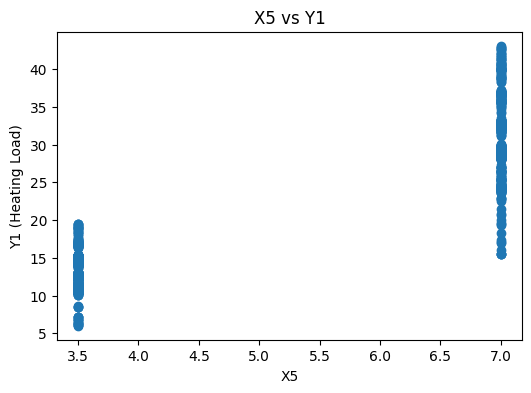

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(df["X5"], df["Y1"])
plt.xlabel("X5")
plt.ylabel("Y1 (Heating Load)")
plt.title("X5 vs Y1")
plt.show()

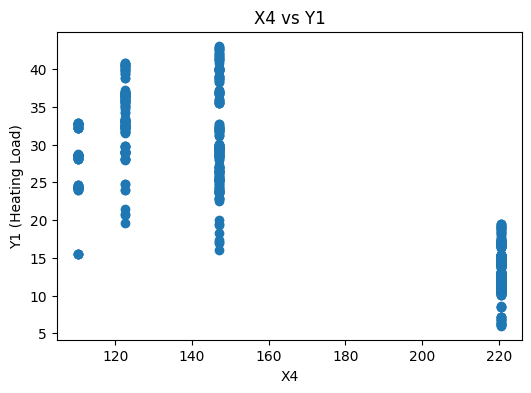

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(df["X4"], df["Y1"])
plt.xlabel("X4")
plt.ylabel("Y1 (Heating Load)")
plt.title("X4 vs Y1")
plt.show()

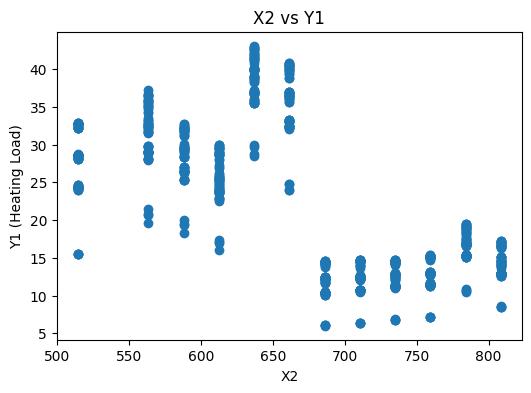

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(df["X2"], df["Y1"])
plt.xlabel("X2")
plt.ylabel("Y1 (Heating Load)")
plt.title("X2 vs Y1")
plt.show()

from these scatter plot choosing X2(surface area) is the best variable hence .

X=X2 (Surface Area)
Y=Y1 (Heating Load)

In [ ]:
X = df[["X2"]]
y = df["Y1"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 1)
Testing data: (154, 1)


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree=1)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)

y_train_pred = model.predict(X_train_poly)
y_test_pred = model.predict(X_test_poly)

In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Degree 1")
print("Training RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)

Degree 1
Training RMSE: 7.505682577369647
Testing RMSE: 7.927730186904961


In [ ]:
degrees = range(1, 11)

train_rmse = []
test_rmse = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)

    train_error = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_error = np.sqrt(mean_squared_error(y_test, y_test_pred))

    train_rmse.append(train_error)
    test_rmse.append(test_error)

In [ ]:
results = pd.DataFrame({
    "Degree": list(degrees),
    "Training RMSE": train_rmse,
    "Testing RMSE": test_rmse
})

results

,Degree,Training RMSE,Testing RMSE
0,1,7.505683,7.927730
1,2,7.405721,7.806331
2,3,6.523038,6.787133
3,4,6.386665,6.622209
4,5,6.416170,6.658382
5,6,6.430146,6.674578
6,7,6.424727,6.666296
7,8,6.397836,6.631214
8,9,6.349476,6.569495
9,10,6.281875,6.483965


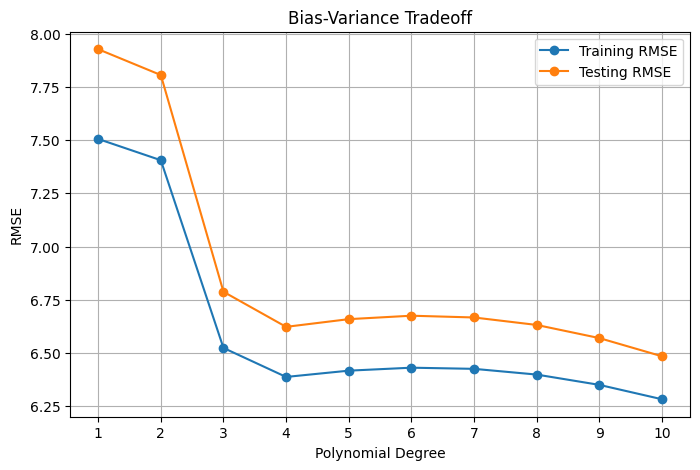

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(list(degrees), train_rmse, marker="o", label="Training RMSE")
plt.plot(list(degrees), test_rmse, marker="o", label="Testing RMSE")

plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE")
plt.title("Bias-Variance Tradeoff")
plt.xticks(list(degrees))
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
best_degree = results.loc[results["Testing RMSE"].idxmin(), "Degree"]
best_test_rmse = results["Testing RMSE"].min()

print("Best polynomial degree:", best_degree)
print("Lowest Testing RMSE:", best_test_rmse)

Best polynomial degree: 10
Lowest Testing RMSE: 6.483965391111112


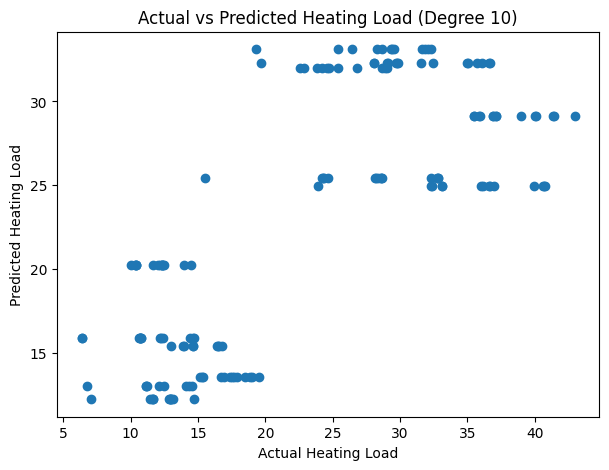

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_test_pred)

plt.xlabel("Actual Heating Load")
plt.ylabel("Predicted Heating Load")
plt.title("Actual vs Predicted Heating Load (Degree 10)")

plt.show()

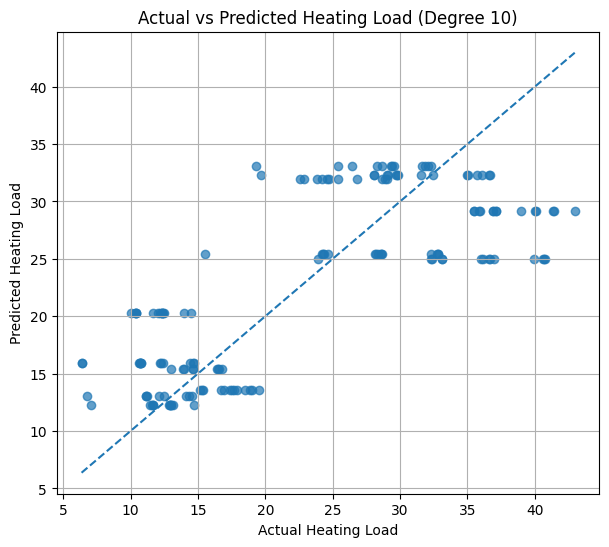

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_test_pred, alpha=0.7)

# Ideal prediction line
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual Heating Load")
plt.ylabel("Predicted Heating Load")
plt.title("Actual vs Predicted Heating Load (Degree 10)")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_test_pred)

print("Final Model: Polynomial Regression (Degree 10)")
print("Test RMSE:", test_rmse[-1])
print("Test R²:", r2)

Final Model: Polynomial Regression (Degree 10)
Test RMSE: 6.483965391111112
Test R²: 0.596653214841754


In [ ]:
best_idx = results["Testing RMSE"].idxmin()

print("Best Degree:", results.loc[best_idx, "Degree"])
print("Lowest Testing RMSE:", results.loc[best_idx, "Testing RMSE"])
print("Training RMSE at Best Degree:", results.loc[best_idx, "Training RMSE"])
print("Test R²:", final_r2)

Best Degree: 10
Lowest Testing RMSE: 6.483965391111112
Training RMSE at Best Degree: 6.2818752126680515
Test R²: 0.596653214841754


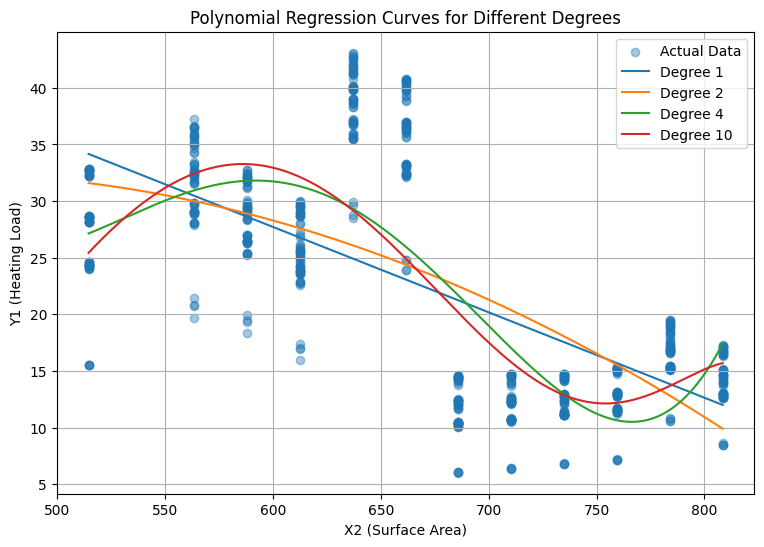

In [ ]:
plt.figure(figsize=(9, 6))

# Actual observations
plt.scatter(X["X2"], y, alpha=0.4, label="Actual Data")

for degree in [1, 2, 4, 10]:
    poly = PolynomialFeatures(degree=degree)

    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    # Smooth X2 values as a DataFrame
    X_curve = pd.DataFrame({
        "X2": np.linspace(X["X2"].min(), X["X2"].max(), 500)
    })

    X_curve_poly = poly.transform(X_curve)
    y_curve = model.predict(X_curve_poly)

    plt.plot(
        X_curve["X2"],
        y_curve,
        label=f"Degree {degree}"
    )

plt.xlabel("X2 (Surface Area)")
plt.ylabel("Y1 (Heating Load)")
plt.title("Polynomial Regression Curves for Different Degrees")
plt.legend()
plt.grid(True)
plt.show()